In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from scipy.linalg import eigh

In [16]:
# ---------------- Class priors ----------------
p0 = 0.35
p1 = 0.65

# ---------------- Class 0 parameters ----------------
m0 = np.array([-0.5, -0.5, -0.5, -0.5])
C0 = 0.25 * np.array([[ 2.0, -0.5,  0.3, 0.0],
                      [-0.5,  1.0, -0.5, 0.0],
                      [ 0.3, -0.5,  1.0, 0.0],
                      [ 0.0,  0.0,  0.0, 2.0]])

# ---------------- Class 1 parameters ----------------
m1 = np.array([1.0, 1.0, 1.0, 1.0])
C1 = np.array([[ 1.0, 0.3, -0.2, 0.0],
               [ 0.3, 2.0,  0.3, 0.0],
               [-0.2, 0.3,  1.0, 0.0],
               [ 0.0, 0.0,  0.0, 3.0]])

# ---------------- Generate 10,000 samples ----------------
rng = np.random.default_rng(5644)          # fixed seed -> same data every time
N = 10000
L = (rng.random(N) >= p0).astype(int)      # label is 1 with probability 0.65
N0 = np.sum(L == 0)
N1 = np.sum(L == 1)

X = np.zeros((N, 4))
X[L == 0] = rng.multivariate_normal(m0, C0, N0, method='cholesky')
X[L == 1] = rng.multivariate_normal(m1, C1, N1, method='cholesky')

# Save the data set (the same X and L are used in Parts A, B and C)
np.savetxt('Q1_data.csv', np.column_stack([X, L]), delimiter=',',
           header='x1,x2,x3,x4,label', comments='')

print('Class 0 samples:', N0)
print('Class 1 samples:', N1)
print('Total samples  :', N)

Class 0 samples: 3460
Class 1 samples: 6540
Total samples  : 10000


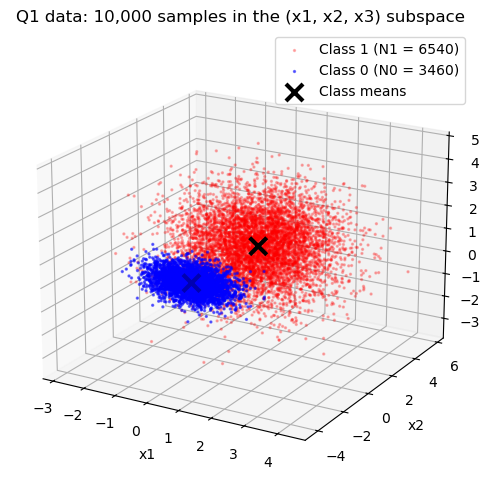

In [17]:
# ---------------- Figure 1: 3D scatter plot ----------------
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection='3d', computed_zorder=False)

# Class 1 is drawn first so the compact class-0 cluster stays visible on top
ax.scatter(X[L == 1, 0], X[L == 1, 1], X[L == 1, 2], s=2, c='red', alpha=0.25,
           label='Class 1 (N1 = ' + str(N1) + ')')
ax.scatter(X[L == 0, 0], X[L == 0, 1], X[L == 0, 2], s=2, c='blue', alpha=0.5,
           label='Class 0 (N0 = ' + str(N0) + ')')
ax.scatter([-0.5, 1], [-0.5, 1], [-0.5, 1], c='black', marker='x', s=150,
           linewidths=3, label='Class means')

ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('x3')
ax.set_title('Q1 data: 10,000 samples in the (x1, x2, x3) subspace')
ax.legend()
ax.view_init(elev=20, azim=-60)

plt.savefig('Fig1_scatter.png', dpi=300)
plt.show()

In [6]:
def roc_curve(score, L, prior0, prior1):
    thresholds = np.concatenate(([-np.inf], np.sort(score)))

    TPR = []  
    FPR = []  
    FNR = []   
    Pe  = []   

    for t in thresholds:
        D = (score > t).astype(int)                         
        tpr = np.sum((D == 1) & (L == 1)) / np.sum(L == 1)
        fpr = np.sum((D == 1) & (L == 0)) / np.sum(L == 0)
        fnr = 1 - tpr
        TPR.append(tpr)
        FPR.append(fpr)
        FNR.append(fnr)
        Pe.append(fpr * prior0 + fnr * prior1)

    return thresholds, np.array(TPR), np.array(FPR), np.array(FNR), np.array(Pe)

In [7]:
gamma_theory = p0 / p1

score_A = multivariate_normal.logpdf(X, m1, C1) - multivariate_normal.logpdf(X, m0, C0)

thr_A, TPR_A, FPR_A, FNR_A, Pe_A = roc_curve(score_A, L, p0, p1)

i_A = np.argmin(Pe_A)
gamma_hat_A = np.exp(thr_A[i_A])

D = (score_A > np.log(gamma_theory)).astype(int)
tpr_th_A = np.sum((D == 1) & (L == 1)) / N1
fpr_th_A = np.sum((D == 1) & (L == 0)) / N0
Pe_th_A  = fpr_th_A * p0 + (1 - tpr_th_A) * p1

print('Theoretical gamma              =', round(gamma_theory, 4))
print('Empirical min-P(error) gamma   =', round(gamma_hat_A, 4))
print('Minimum empirical P(error)     =', round(Pe_A[i_A], 4))
print('Operating point: FPR =', round(FPR_A[i_A], 4), ', TPR =', round(TPR_A[i_A], 4))
print('P(error) at theoretical gamma  =', round(Pe_th_A, 4),
      '(FPR =', round(fpr_th_A, 4), ', TPR =', round(tpr_th_A, 4), ')')

Theoretical gamma              = 0.5385
Empirical min-P(error) gamma   = 0.6231
Minimum empirical P(error)     = 0.0251
Operating point: FPR = 0.0211 , TPR = 0.9728
P(error) at theoretical gamma  = 0.0255 (FPR = 0.0246 , TPR = 0.974 )


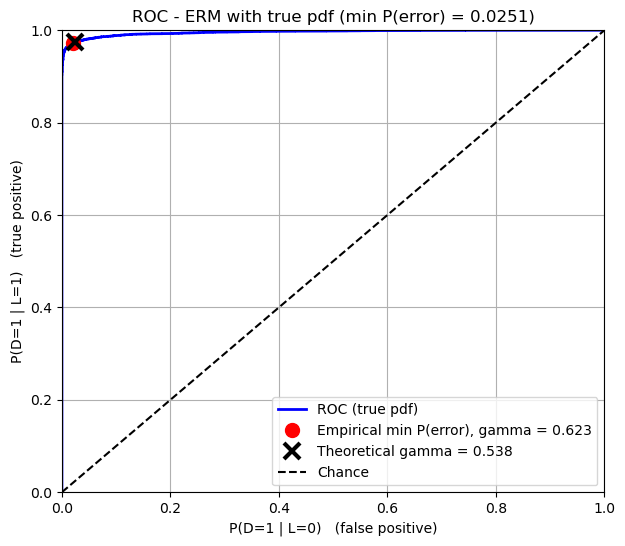

In [18]:
# ---------------- Figure 2: ROC curve of the true-pdf classifier ----------------
plt.figure(figsize=(7, 6))
plt.plot(FPR_A, TPR_A, 'b-', linewidth=2, label='ROC (true pdf)')
plt.plot(FPR_A[i_A], TPR_A[i_A], 'ro', markersize=10,
         label='Empirical min P(error), gamma = ' + str(round(gamma_hat_A, 3)))
plt.plot(fpr_th_A, tpr_th_A, 'kx', markersize=12, markeredgewidth=3,
         label='Theoretical gamma = ' + str(round(gamma_theory, 3)))
plt.plot([0, 1], [0, 1], 'k--', label='Chance')

plt.xlabel('P(D=1 | L=0)   (false positive)')
plt.ylabel('P(D=1 | L=1)   (true positive)')
plt.title('ROC - ERM with true pdf (min P(error) = ' + str(round(Pe_A[i_A], 4)) + ')')
plt.legend(loc='lower right')
plt.grid(True)
plt.xlim(0, 1)
plt.ylim(0, 1)

plt.savefig('Fig2_ROC_true.png', dpi=300)
plt.show()

In [19]:
C0_NB = np.diag(np.diag(C0))
C1_NB = np.diag(np.diag(C1))
print('C0_NB diagonal:', np.diag(C0_NB))
print('C1_NB diagonal:', np.diag(C1_NB))

score_B = multivariate_normal.logpdf(X, m1, C1_NB) - multivariate_normal.logpdf(X, m0, C0_NB)

thr_B, TPR_B, FPR_B, FNR_B, Pe_B = roc_curve(score_B, L, p0, p1)

i_B = np.argmin(Pe_B)
gamma_hat_B = np.exp(thr_B[i_B])

# Performance at the theoretical threshold
D = (score_B > np.log(gamma_theory)).astype(int)
tpr_th_B = np.sum((D == 1) & (L == 1)) / N1
fpr_th_B = np.sum((D == 1) & (L == 0)) / N0
Pe_th_B  = fpr_th_B * p0 + (1 - tpr_th_B) * p1

print()
print('Empirical min-P(error) gamma   =', round(gamma_hat_B, 4))
print('Minimum empirical P(error)     =', round(Pe_B[i_B], 4))
print('Operating point: FPR =', round(FPR_B[i_B], 4), ', TPR =', round(TPR_B[i_B], 4))
print('P(error) at theoretical gamma  =', round(Pe_th_B, 4),
      '(FPR =', round(fpr_th_B, 4), ', TPR =', round(tpr_th_B, 4), ')')

C0_NB diagonal: [0.5  0.25 0.25 0.5 ]
C1_NB diagonal: [1. 2. 1. 3.]

Empirical min-P(error) gamma   = 0.4586
Minimum empirical P(error)     = 0.0313
Operating point: FPR = 0.0344 , TPR = 0.9703
P(error) at theoretical gamma  = 0.032 (FPR = 0.0321 , TPR = 0.968 )


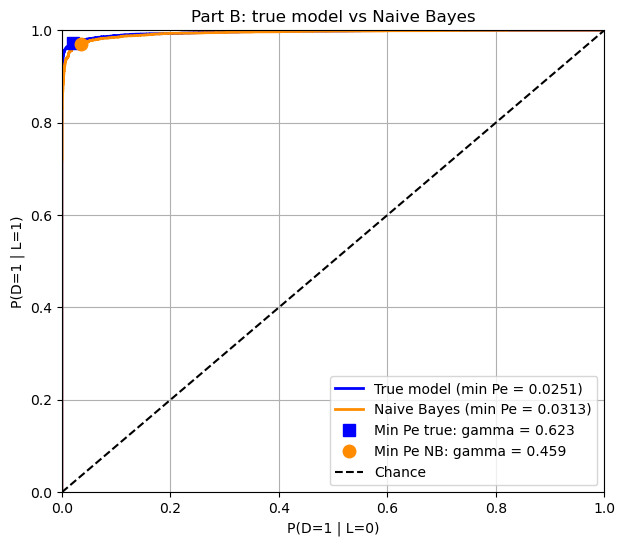

In [20]:
plt.figure(figsize=(7, 6))
plt.plot(FPR_A, TPR_A, 'b-', linewidth=2,
         label='True model (min Pe = ' + str(round(Pe_A[i_A], 4)) + ')')
plt.plot(FPR_B, TPR_B, '-', color='darkorange', linewidth=2,
         label='Naive Bayes (min Pe = ' + str(round(Pe_B[i_B], 4)) + ')')
plt.plot(FPR_A[i_A], TPR_A[i_A], 'bs', markersize=9,
         label='Min Pe true: gamma = ' + str(round(gamma_hat_A, 3)))
plt.plot(FPR_B[i_B], TPR_B[i_B], 'o', color='darkorange', markersize=9,
         label='Min Pe NB: gamma = ' + str(round(gamma_hat_B, 3)))
plt.plot([0, 1], [0, 1], 'k--', label='Chance')

plt.xlabel('P(D=1 | L=0)')
plt.ylabel('P(D=1 | L=1)')
plt.title('Part B: true model vs Naive Bayes')
plt.legend(loc='lower right')
plt.grid(True)
plt.xlim(0, 1)
plt.ylim(0, 1)

plt.savefig('Fig3_ROC_true_vs_NB.png', dpi=300)
plt.show()

In [12]:
# ---------------- Part C: Fisher LDA ----------------
X0 = X[L == 0]
X1 = X[L == 1]

mu0_hat = np.mean(X0, axis=0)
mu1_hat = np.mean(X1, axis=0)

C0_hat = np.cov(X0.T, bias=True)
C1_hat = np.cov(X1.T, bias=True)

Sb = np.outer(mu1_hat - mu0_hat, mu1_hat - mu0_hat)
Sw = C0_hat + C1_hat

eigvals, eigvecs = eigh(Sb, Sw)      
w_LDA = eigvecs[:, -1]            

if w_LDA @ (mu1_hat - mu0_hat) < 0:
    w_LDA = -w_LDA

score_C = X @ w_LDA
thr_C, TPR_C, FPR_C, FNR_C, Pe_C = roc_curve(score_C, L, N0 / N, N1 / N)   

i_C = np.argmin(Pe_C)
tau_hat = thr_C[i_C]

print('w_LDA =', np.round(w_LDA, 4))
print('Optimal threshold tau          =', round(tau_hat, 4))
print('Minimum empirical P(error)     =', round(Pe_C[i_C], 4))
print('Operating point: FPR =', round(FPR_C[i_C], 4), ', TPR =', round(TPR_C[i_C], 4))

w_LDA = [0.4738 0.2161 0.56   0.2014]
Optimal threshold tau          = 0.0014
Minimum empirical P(error)     = 0.0523
Operating point: FPR = 0.0555 , TPR = 0.9494


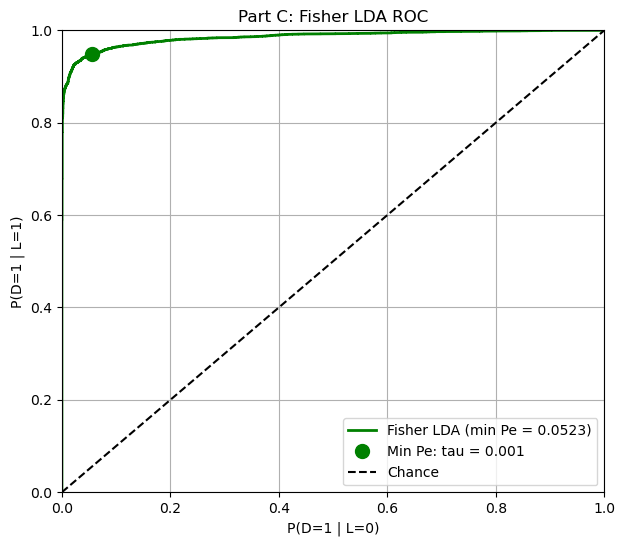

In [13]:
# ---------------- Figure 4: ROC of Fisher LDA ----------------
plt.figure(figsize=(7, 6))
plt.plot(FPR_C, TPR_C, '-', color='green', linewidth=2,
         label='Fisher LDA (min Pe = ' + str(round(Pe_C[i_C], 4)) + ')')
plt.plot(FPR_C[i_C], TPR_C[i_C], 'o', color='green', markersize=10,
         label='Min Pe: tau = ' + str(round(tau_hat, 3)))
plt.plot([0, 1], [0, 1], 'k--', label='Chance')

plt.xlabel('P(D=1 | L=0)')
plt.ylabel('P(D=1 | L=1)')
plt.title('Part C: Fisher LDA ROC')
plt.legend(loc='lower right')
plt.grid(True)
plt.xlim(0, 1)
plt.ylim(0, 1)

plt.savefig('Fig5_ROC_LDA.png', dpi=300)
plt.show()